# Шаблон исследования: проверка торговой идеи

> Копируйте этот ноутбук в `research/<exp_NN_название>/`. Идея ноутбука — чтобы между «пришла мысль» и «есть честный ответ»
> оставалось только определить признак и сигнал. Все тяжелые части (данные, проверки качества, исполнение, статистика)
> берутся из проекта и **не переписываются под идею**.

**Правила (нарушение любого делает результат недействительным):**
1. Гипотеза и параметры фиксируются **до** просмотра результатов (раздел 1). Изменение после — только с записью «пост-фактум».
2. Любой признак — функция только прошлого (раздел 4, чек-лист).
3. Данные проходят проверки качества до анализа (раздел 3). WARN/FAIL объясняются, а не игнорируются.
4. Сначала валовая оценка (без издержек), потом издержки — иначе не видно, чем убит результат.
5. Значимость — плацебо-перестановками по суткам, с поправкой на число проверенных активов/вариантов.
6. Каждая встреченная проблема записывается в `PROBLEMS.md` рядом с ноутбуком: что → почему → как устранили.

## 1. Предрегистрация (заполнить ДО расчетов)

| Поле | Значение |
|---|---|
| **Гипотеза** | _одно предложение: что и в каком направлении предсказывает_ |
| **Механизм** | _почему это должно работать (кто на другой стороне сделки, какая неэффективность)_ |
| **Что опровергнет** | _числовые критерии отказа, напр. «edge < 1 б.п. или q > 0.1 в обоих подпериодах»_ |
| **Вселенная** | _активы и критерий отбора_ |
| **Период / разбиение** | _даты; граница подпериодов для проверки устойчивости_ |
| **Издержки** | _комиссия taker/maker, спред, проскальзывание_ |
| **Число проверяемых вариантов** | _нужно для поправки на множественные сравнения_ |

In [1]:
import sys, pathlib
from dataclasses import dataclass
from datetime import date

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "backtest_strat").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from backtest_strat.derived import derive_symbol
from backtest_strat.research.market import instrument_specs, spread_snapshot
from backtest_strat.research import stats
from backtest_strat.research.bars import minute_bars, to_hourly
from backtest_strat.research.evaluate import fast_pnl, run_schedule
from backtest_strat.validation import validate_symbol

pd.options.display.float_format = "{:,.3f}".format


@dataclass(frozen=True)
class Params:                       # ЗАМОРОЖЕНО до первого прогона
    exchange: str = "okx"
    symbols: tuple = ("BTC-USDT",)
    start: date = date(2024, 1, 1)
    end: date = date(2024, 1, 31)   # последний UTC-день, покрытый сделками D и D+1
    split: date = date(2024, 1, 16) # граница подпериодов
    lookback_days: int = 7          # окно признака (пример)
    t_threshold: float = 1.0
    notional: float = 1_000.0
    taker_fee_bps: float = 10.0
    placebo_draws: int = 300
    placebo_min_shift_days: int = 3
    seed: int = 1

P = Params()
PROC = str(ROOT / "data/processed")
rng = np.random.default_rng(P.seed)

## 2. Данные: довести пайплайн до нужного слоя

Данные собираются утилитами проекта (идемпотентно). Для идей на барах достаточно **только сделок**:

```bash
python -m backtest_strat.cli --exchange okx --symbol BTC-USDT --mode backfill --start 2024-01-01 --end 2024-01-31 \
       --data-type trades --stage all
```
Стадия `all` скачает, нормализует, проверит и построит бары `bars_1s`/`bars_1m`. Стакан нужен только если идея
использует глубину/очередь (тогда `--data-type trades orderbook`, ≈1–4 ГБ/день на актив).

In [2]:
rows = []
for s in P.symbols:
    v = validate_symbol(s, P.exchange, PROC, P.start, P.end)
    d = derive_symbol(s, P.exchange, PROC, P.start, P.end)
    rows.append({"symbol": s, **{k: sum(x["status"] == k for x in v.days) for k in ("OK", "WARN", "FAIL")},
                 "missing_days": len(v.missing_days), "derive_failed": sum(r.status == "failed" for r in d.results)})
quality = pd.DataFrame(rows).set_index("symbol")
quality

,OK,WARN,FAIL,missing_days,derive_failed
symbol,,,,,
BTC-USDT,29,2,0,0,0


**Чек-лист качества.** Если есть WARN/FAIL — выпишите причины и решение (исключить день / актив / принять):

In [3]:
for s in P.symbols:
    v = validate_symbol(s, P.exchange, PROC, P.start, P.end)
    for d in v.days:
        if d["status"] != "OK":
            print(s, d["day"], d["status"], [(c["name"], c["detail"][:90]) for c in d["checks"] if c["status"] != "OK"])

BTC-USDT 2024-01-02 WARN [('no_initial_book', 'Файл начинается с апдейтов: книга неполна первые 60s суток (первый снапшот в 2024-01-02T00')]
BTC-USDT 2024-01-03 WARN [('book_gap', 'Макс. пауза 68.8s; > 30s: 1, > 300s: 0'), ('price_spike', '20 скачков > 50 б.п. за 1s с возвратом')]


## 3. Спецификации и издержки

Шаг цены и лот — из биржи; спред — снимок биржи (прокси; для точности нужен L1 из стакана). Не оценивайте спред
по high/low баров: в крипте это завышает его на порядки (см. журнал проблем exp01, P5).

In [4]:
specs = instrument_specs(P.exchange)
spreads = spread_snapshot(P.exchange)
pd.DataFrame({s: {**specs[s], "snapshot_spread_bps": spreads[s]} for s in P.symbols}).T

,tick_size,lot_size,min_size,multiplier,snapshot_spread_bps
BTC-USDT,0.100,0.000,0.000,1.000,0.012


## 4. Признаки

**Чек-лист «точка во времени» (отметьте каждый пункт):**
- [ ] Признак в строке `t` использует только данные, **полностью известные** к моменту `t` (проверьте shift/rolling).
- [ ] Внешние ряды сдвинуты на задержку публикации (`backtest_strat/external/weather.py::load_daily(lag_days=1)`).
- [ ] Нормировки (среднее/std/квантили) считаются по скользящему окну прошлого, а не по всей выборке.
- [ ] Цена исполнения = цена, доступная на момент решения, а не «закрытие бара, который еще идет».
- [ ] Пропуски заполняются только вперед (`ffill`), никогда назад.

Строка `t` — период, **начинающийся** в `t`; `ret` — доходность, которую позиция заработает внутри периода.

In [5]:
def build_features(hourly: pd.DataFrame) -> pd.DataFrame:
    f = pd.DataFrame(index=hourly.index)
    f["ret"] = np.log(hourly["close"] / hourly["close"].shift(1))      # доходность внутри часа t
    # --- ПРИМЕР: среднее той же доходности в тот же час за предыдущие N дней ---
    g = f["ret"].groupby(f.index.hour)
    f["mu"] = g.transform(lambda s: s.shift(1).rolling(P.lookback_days, min_periods=P.lookback_days).mean())
    f["sd"] = g.transform(lambda s: s.shift(1).rolling(P.lookback_days, min_periods=P.lookback_days).std())
    f["t"] = f["mu"] / (f["sd"] / np.sqrt(P.lookback_days))
    return f


def build_positions(f: pd.DataFrame) -> pd.Series:
    """Целевая позиция -1/0/+1, принимаемая в начале часа t по информации до t."""
    return pd.Series(np.where(f["t"].abs() >= P.t_threshold, np.sign(f["mu"]), 0.0), index=f.index).fillna(0.0)

In [6]:
data = {}
for s in P.symbols:
    m = minute_bars(s, P.start, P.end, P.exchange, PROC)
    h = to_hourly(m)
    f = build_features(h)
    data[s] = {"minute": m, "hourly": h, "f": f, "pos": build_positions(f)}
    print(s, "минутных баров:", len(m), "| часов:", len(h), "| часов в позиции:", int((data[s]["pos"] != 0).sum()))

BTC-USDT минутных баров: 44640 | часов: 744 | часов в позиции: 216


## 5. Валовая оценка и плацебо

Сначала **без издержек**: есть ли вообще связь сигнала с будущей доходностью. Плацебо — тот же сигнал,
циклически сдвинутый на случайное число суток (сохраняет структуру, ломает связь с рынком).

In [7]:
res = []
for s, d in data.items():
    f, pos = d["f"], d["pos"]
    valid = f["mu"].notna()
    r = np.expm1(f["ret"].where(valid).fillna(0.0)).to_numpy()
    sig = pos.where(valid, 0.0).to_numpy()
    e = stats.placebo_edge(sig * r, sig, r, rng, P.placebo_draws, P.placebo_min_shift_days)
    gross = fast_pnl(f["ret"].where(valid), pos.where(valid, 0.0), 0.0, P.notional)
    res.append({"symbol": s, "edge_bps": e["edge_bps"], "p_placebo": e["p"], "active_hours": e["n_active"],
                "gross_pnl_usd": gross.sum(), "daily_t": stats.daily_tstat(gross[valid])})
scorecard = pd.DataFrame(res).set_index("symbol")
scorecard["q_bh"] = stats.benjamini_hochberg(scorecard["p_placebo"])
scorecard

,edge_bps,p_placebo,active_hours,gross_pnl_usd,daily_t,q_bh
symbol,,,,,,
BTC-USDT,-3.764,0.395,216,-81.299,-0.921,0.395


## 6. Исполнение через движок и чувствительность к издержкам

Расписание позиций исполняется движком проекта на синтетическом стакане из минутных баров
(`backtest_strat/backtest/bar_feed.py`). Расхождение с быстрой оценкой должно быть пренебрежимо мало относительно оборота (≲ 0.1%) — это проверка, что расчет верен;
относительная ошибка на PnL, близком к нулю, не показательна.

In [8]:
rows = []
for s, d in data.items():
    f, pos = d["f"], d["pos"]
    valid = f["mu"].notna()
    pv = pos.where(valid, 0.0)
    half = max(spreads[s] / 2, specs[s]["tick_size"] / float(d["hourly"]["close"].median()) * 1e4 / 2)
    for fee in (P.taker_fee_bps, 2.0, 0.0):
        eng = run_schedule(d["minute"], pv, s, specs[s]["tick_size"], specs[s]["lot_size"], half, fee, P.notional)
        fast = fast_pnl(f["ret"].where(valid), pv, fee + half, P.notional)[valid].sum()
        rows.append({"symbol": s, "fee_bps": fee, "engine_pnl": eng["net_pnl"], "fast_pnl": fast,
                     "diff_usd": eng["net_pnl"] - fast, "diff_pct_of_turnover": (eng["net_pnl"] - fast) / max(1.0, eng["notional_traded"]) * 100,
                     "fills": eng["fills"]})
pd.DataFrame(rows).set_index(["symbol", "fee_bps"])

engine_pnl  fast_pnl  diff_usd  diff_pct_of_turnover  fills
symbol   fee_bps                                                             
BTC-USDT 10.000     -464.333  -463.745    -0.587                -0.000    329
         2.000      -159.023  -158.145    -0.877                -0.000    329
         0.000       -82.695   -81.745    -0.950                -0.000    329

## 7. Устойчивость: два подпериода

Закономерность, живущая только в одной половине выборки, — кандидат в артефакты.

In [9]:
rows = []
for s, d in data.items():
    f, pos = d["f"], d["pos"]
    valid = f["mu"].notna()
    g = fast_pnl(f["ret"].where(valid), pos.where(valid, 0.0), 0.0, P.notional)[valid]
    a, b = g[g.index < pd.Timestamp(P.split)], g[g.index >= pd.Timestamp(P.split)]
    rows.append({"symbol": s, "gross_bps_h1": a.mean() / P.notional * 1e4, "gross_bps_h2": b.mean() / P.notional * 1e4,
                 "same_sign": np.sign(a.mean()) == np.sign(b.mean())})
pd.DataFrame(rows).set_index("symbol")

,gross_bps_h1,gross_bps_h2,same_sign
symbol,,,
BTC-USDT,-2.303,-0.972,True


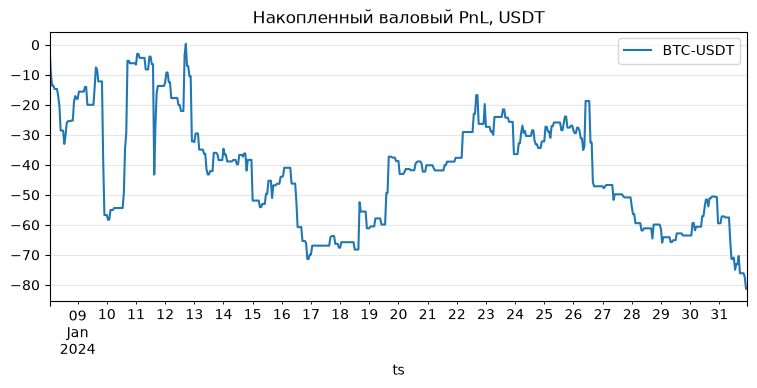

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for s, d in data.items():
    f, pos = d["f"], d["pos"]
    valid = f["mu"].notna()
    fast_pnl(f["ret"].where(valid), pos.where(valid, 0.0), 0.0, P.notional)[valid].cumsum().plot(ax=ax, label=s)
ax.set_title("Накопленный валовый PnL, USDT"); ax.legend(); ax.grid(alpha=.3)

## 8. Решение

Заполняется по критериям из раздела 1, **не** по ощущениям:

| Критерий | Порог | Факт | Выполнен |
|---|---|---|---|
| Валовый edge | | | |
| Значимость (q по BH) | | | |
| Устойчивость (оба подпериода) | | | |
| Чистый результат после издержек | | | |
| Расхождение движка и быстрой оценки | ≤ 0.1% оборота | | |

**Вывод:** _идея подтверждена / отклонена / требует других данных_

**Проблемы и обходы** → `PROBLEMS.md`